# DL A3

###Name : Hafsah Zulqarnain
###Roll No: 25280045



## Colab setup and dataset download

In [1]:
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub', 'tables'])

0

In [2]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import shutil
DATA = Path('/content/largest_data')
OUT = Path('/content/drive/MyDrive/DL_A3_results_P2')
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
print('Temporary dataset folder:', DATA)
print('Persistent results folder:', OUT)
print(f"Free Colab disk: {shutil.disk_usage('/content').free / 1024**3:.1f} GiB")

Mounted at /content/drive
Temporary dataset folder: /content/largest_data
Persistent results folder: /content/drive/MyDrive/DL_A3_results_P2
Free Colab disk: 112.5 GiB


In [3]:
import kagglehub, os
required = ['ca_meta.csv', 'ca_rn_adj.npy', 'ca_his_raw_2020.h5', 'ca_his_raw_2021.h5']
for name in required:
    target = DATA / name
    if target.exists():
        print('Already downloaded:', name)
        continue
    print('Downloading:', name)
    try:
        downloaded = Path(kagglehub.dataset_download('liuxu77/largest', path=name))
        if not downloaded.is_file():
            raise FileNotFoundError(f'Expected a file, got {downloaded}')
        target.symlink_to(downloaded.resolve())
    except Exception as exc:
        raise RuntimeError(f'Could not obtain {name}. Check Kaggle access, token, filename, and Colab disk space: {exc}') from exc
    print(f"Free Colab disk: {shutil.disk_usage('/content').free / 1024**3:.1f} GiB")
print('Required files ready:', [p.name for p in DATA.iterdir()])

Downloading: ca_meta.csv
Using Colab cache for faster access to the 'largest' dataset.
Free Colab disk: 112.5 GiB
Downloading: ca_rn_adj.npy
Using Colab cache for faster access to the 'largest' dataset.
Free Colab disk: 112.5 GiB
Downloading: ca_his_raw_2020.h5
Using Colab cache for faster access to the 'largest' dataset.
Free Colab disk: 112.5 GiB
Downloading: ca_his_raw_2021.h5
Using Colab cache for faster access to the 'largest' dataset.
Free Colab disk: 112.5 GiB
Required files ready: ['ca_meta.csv', 'ca_his_raw_2020.h5', 'ca_his_raw_2021.h5', 'ca_rn_adj.npy']


### Dataset-format check


In [4]:

import os, time, random, json, platform, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

assert DATA.exists() and OUT.exists()
SEED=42; BATCH=32; HIDDEN=16; EMBED=8; EPOCHS=15; PATIENCE=3; LR=1e-3
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
print('Device:', DEVICE, 'Python:', platform.python_version(), 'PyTorch:', torch.__version__, 'CPU:', platform.processor())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')

Device: cuda Python: 3.13.16 PyTorch: 2.14.1+cu130 CPU: x86_64
GPU: Tesla T4


#Question 3

## Q3(a):  Data Extraction and Resampling

Metadata columns: ['ID', 'Lat', 'Lng', 'District', 'County', 'Fwy', 'Lanes', 'Type', 'Direction', 'ID2']

Processing 2020...
HDF5 keys: ['/t']
  Read 4,032 five-minute rows
  Read 8,064 five-minute rows
  Read 12,096 five-minute rows
  Read 16,128 five-minute rows
  Read 20,160 five-minute rows
  Read 24,192 five-minute rows
  Read 28,224 five-minute rows
  Read 32,256 five-minute rows
  Read 36,288 five-minute rows
  Read 40,320 five-minute rows
  Read 44,352 five-minute rows
  Read 48,384 five-minute rows
  Read 52,416 five-minute rows
  Read 56,448 five-minute rows
  Read 60,480 five-minute rows
  Read 64,512 five-minute rows
  Read 68,544 five-minute rows
  Read 72,576 five-minute rows
  Read 76,608 five-minute rows
  Read 80,640 five-minute rows
  Read 84,672 five-minute rows
  Read 88,704 five-minute rows
  Read 92,736 five-minute rows
  Read 96,768 five-minute rows
  Read 100,800 five-minute rows
  Read 104,832 five-minute rows
  Read 105,408 five-minute rows
2020 5-minute missi

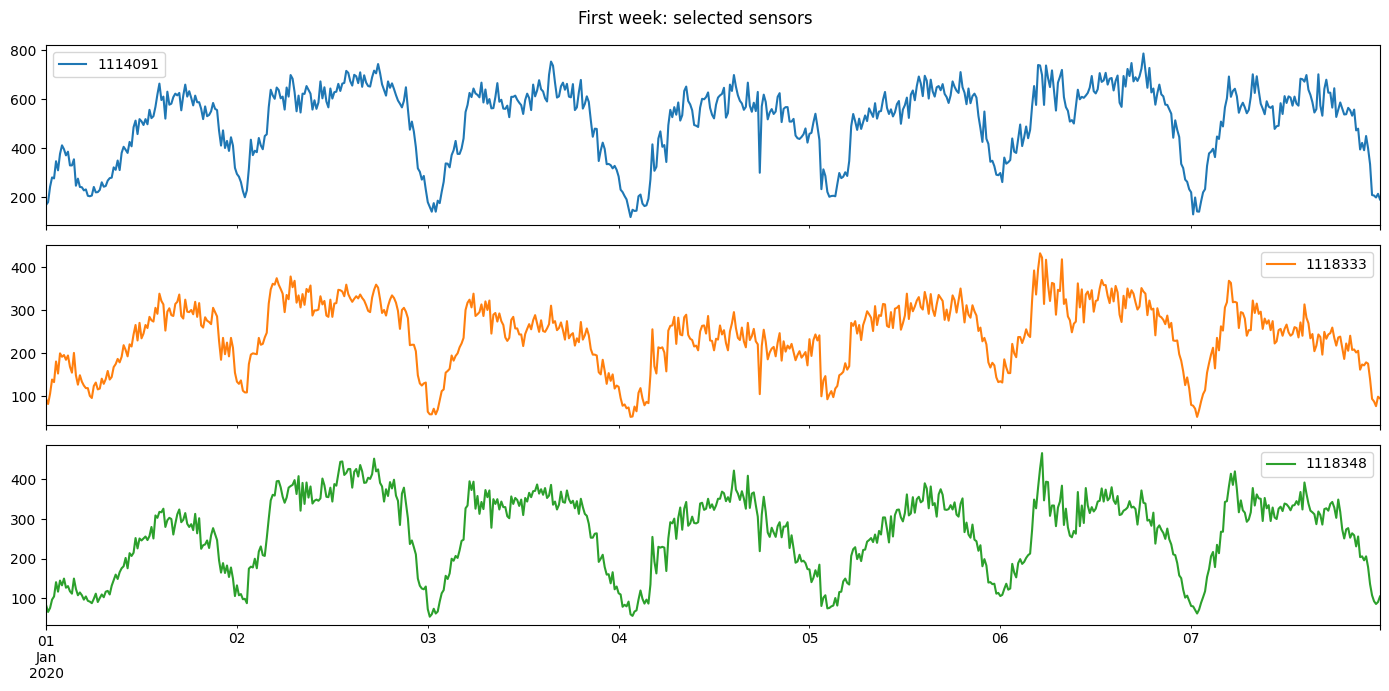

In [6]:
meta=pd.read_csv(DATA/'ca_meta.csv')
print('Metadata columns:', list(meta.columns))
cols={c.lower():c for c in meta.columns}
id_col=cols.get('id', cols.get('sensor_id'))
district_col=cols.get('district')
assert id_col and district_col, 'Identify metadata sensor ID and district columns above and adjust id_col/district_col.'
meta[id_col]=meta[id_col].astype(str).str.replace(r'\.0$', '', regex=True)
assert meta[id_col].is_unique
mask=meta[district_col].astype(str).str.replace(r'\.0$', '', regex=True).eq('11').to_numpy()
assert mask.sum()==716, f'Expected 716 SD nodes, got {mask.sum()}'
ids=meta.loc[mask,id_col].tolist(); sdmeta=meta.loc[mask].reset_index(drop=True)
Afull=np.load(DATA/'ca_rn_adj.npy')
assert Afull.shape==(len(meta),len(meta)), 'Adjacency dimensions do not match metadata.'
A=Afull[np.ix_(mask,mask)].astype('float32'); np.fill_diagonal(A,0)
assert np.isfinite(A).all() and (A>=0).all()
del Afull
import gc


CHUNK_ROWS = 4032

frames = []

for year in [2020, 2021]:
    file_path = DATA / f"ca_his_raw_{year}.h5"
    selected_chunks = []

    print(f"\nProcessing {year}...", flush=True)

    with pd.HDFStore(file_path, mode="r") as store:
        keys = store.keys()
        print("HDF5 keys:", keys, flush=True)

        if len(keys) != 1:
            raise ValueError(
                "This file has multiple HDF5 keys. "
                f"Please share the list above so we can select the correct one."
            )

        key = keys[0]
        start = 0

        while True:
            chunk = store.select(
                key,
                start=start,
                stop=start + CHUNK_ROWS
            )

            if chunk.empty:
                break

            rows_read = len(chunk)

            chunk.columns = (
                chunk.columns.map(str)
                .str.replace(r"\.0$", "", regex=True)
            )

            if not chunk.columns.is_unique:
                raise ValueError("Traffic data contains duplicate sensor IDs.")

            missing_ids = set(ids) - set(chunk.columns)
            if missing_ids:
                raise ValueError(
                    f"{len(missing_ids)} San Diego sensor IDs were not found. "
                    f"Examples: {list(missing_ids)[:5]}"
                )

            sd_chunk = chunk.loc[:, ids].astype("float32").copy()
            sd_chunk.index = pd.to_datetime(sd_chunk.index)
            selected_chunks.append(sd_chunk)

            del chunk, sd_chunk
            gc.collect()

            start += rows_read
            print(f"  Read {start:,} five-minute rows", flush=True)

            if rows_read < CHUNK_ROWS:
                break

    if not selected_chunks:
        raise ValueError(f"No data was read for {year}.")

    frame = pd.concat(selected_chunks)
    del selected_chunks
    gc.collect()

    if not frame.index.is_unique:
        raise ValueError(f"Duplicate timestamps found in {year}.")

    frame = frame.sort_index()
    frame = frame.replace([np.inf, -np.inf], np.nan)

    frame = frame.loc[
        (frame.index >= f"{year}-01-01") &
        (frame.index < f"{year + 1}-01-01")
    ]

    print(
        year,
        "5-minute missing fraction:",
        frame.isna().mean().mean(),
        flush=True
    )

    lanes = sdmeta['Lanes'].to_numpy()
    print((frame.max() / lanes).describe())   # per-lane peak
    print(frame.quantile(0.999).describe())

    sums   = frame.resample("15min").sum()          # NaNs are skipped by default
    counts = frame.resample("15min").count()
    frames.append(sums.where(counts == 3).astype("float32"))

    del frame, sums, counts
    gc.collect()

raw = pd.concat(frames).reindex(
    pd.date_range(
        "2020-01-01",
        "2022-01-01",
        freq="15min",
        inclusive="left"
    )
)

assert raw.shape[1] == 716
assert raw.columns.tolist() == ids

print("15-minute shape:", raw.shape)
print("Missing fraction:", raw.isna().mean().mean())

raw.iloc[:7 * 96, [0, 1, 2]].plot(
    subplots=True,
    figsize=(14, 7),
    title="First week: selected sensors"
)

plt.tight_layout()
plt.savefig(OUT / "week.png", dpi=150)
plt.show()

## Q3(b–c): Constructing the Traffic Graph - Understanding Graph Neighborhoods

A nonzero entry \(Aij\) means that sensors \(i\) and \(j\) are connected in the traffic graph. The value represents the strength of their relationship, which is based on the road distance between them. A zero means that no connection is recorded between those sensors in the graph. The model uses these connections to include information from other sensors when making predictions.

Nodes: 716 nonzero off-diagonal entries: 17319 symmetric: False
Degree min/mean/max: 0 24.18854748603352 70


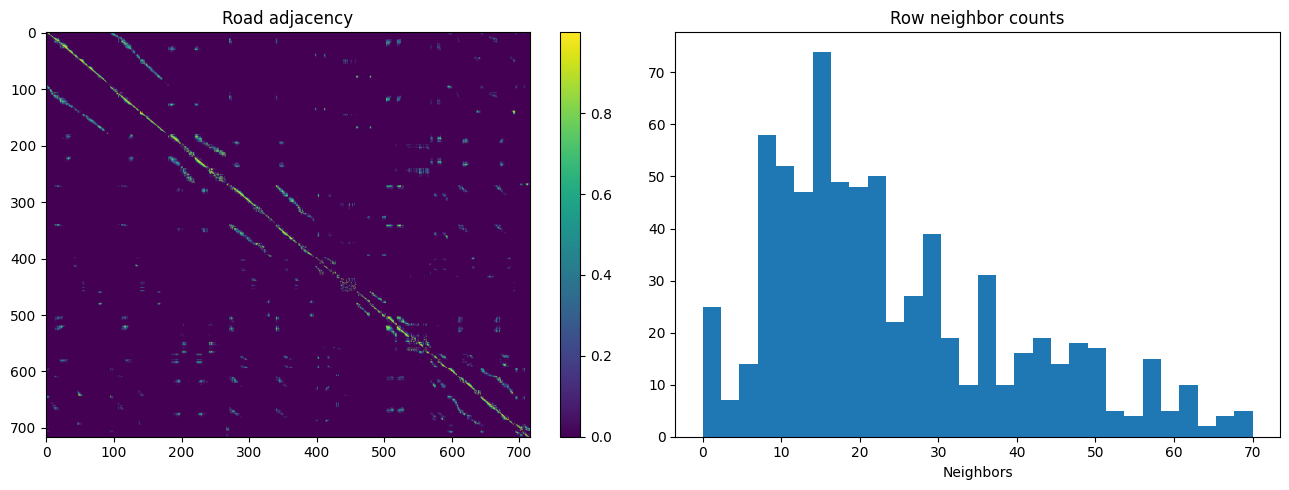

Selected sensor: 1114091
One-hop IDs: ['1118333', '1118348', '1114720', '1114228', '1118326', '1118341', '1114721', '1119784', '1119797', '1118663', '1118677', '1126361', '1126368', '1119790', '1118656', '1118670', '1119804', '1125836', '1125835', '1125812', '1125805', '1126526', '1125348']
At most two-hop IDs: ['1118333', '1118348', '1114720', '1118352', '1118743', '1114228', '1118326', '1118341', '1114721', '1118365', '1118372', '1118379', '1119784', '1119797', '1118663', '1118677', '1126361', '1126368', '1122699', '1116061', '1115905', '1116055', '1119790', '1118656', '1118670', '1119804', '1122706', '1115912', '1115979', '1115972', '1125836', '1125835', '1125812', '1125805', '1125799', '1125794', '1123302', '1123282', '1122380', '1126526', '1125829', '1125348', '1125353', '1125359', '1123287', '1123276']
Nearby sensors can provide early information about congestion propagation; two-hop aggregation also uses neighbors of neighbors.


In [7]:
B=A>0; np.fill_diagonal(B,False)
print('Nodes:',len(ids),'nonzero off-diagonal entries:',int(B.sum()),'symmetric:',np.allclose(A,A.T))
print('Degree min/mean/max:', B.sum(1).min(),B.sum(1).mean(),B.sum(1).max())
fig,ax=plt.subplots(1,2,figsize=(13,5)); im=ax[0].imshow(A,aspect='auto'); fig.colorbar(im,ax=ax[0]); ax[0].set_title('Road adjacency'); ax[1].hist(B.sum(1),bins=30); ax[1].set_title('Row neighbor counts'); ax[1].set_xlabel('Neighbors'); plt.tight_layout(); plt.savefig(OUT/'road_graph.png',dpi=150); plt.show()
i=0; one=set(np.flatnonzero(B[i])); two=set(one)
for j in one: two.update(np.flatnonzero(B[j]))
two.discard(i)
print('Selected sensor:',ids[i]); print('One-hop IDs:',[ids[j] for j in sorted(one)]); print('At most two-hop IDs:',[ids[j] for j in sorted(two)])
print('Nearby sensors can provide early information about congestion propagation; two-hop aggregation also uses neighbors of neighbors.')

# Question 4

## Q4(a): Spatio-Temporal Traffic Forecasting


In [8]:
periods={'train':('2020-01-01','2021-01-01'),'validation':('2021-01-01','2021-04-01'),'test':('2021-04-01','2022-01-01')}
parts={k:raw.loc[(raw.index>=a)&(raw.index<b)].copy() for k,(a,b) in periods.items()}
train = parts["train"]

counts = train.count()
means = train.mean()
std = train.std()
med = train.median()

no_training_data = counts == 0

print(
    "Sensors without training observations:",
    int(no_training_data.sum())
)
print(
    "Affected sensor IDs:",
    train.columns[no_training_data].tolist()
)


fallback_mean = (means.fillna(0) * counts).sum() / counts.sum()
valid_std = std[(std > 0) & std.notna()]
assert counts.sum() > 0 and len(valid_std) > 0, (
    "Insufficient observed training data to calculate fallback statistics."
)
fallback_std = valid_std.median()

means = means.fillna(fallback_mean)
med = med.fillna(fallback_mean)


std = std.mask((std == 0) | (std.isna() & ~no_training_data), 1.0)

std = std.mask(no_training_data, fallback_std)

assert means.notna().all() and med.notna().all()
assert std.notna().all() and (std > 0).all()

print("Fallback mean:", fallback_mean)
print("Fallback standard deviation:", fallback_std)

datasets = {}
class Windows(Dataset):
    def __init__(self,df):
        self.index=df.index
        self.mask=np.isfinite(df.to_numpy()).astype('float32')
        filled=df.ffill().fillna(med)
        self.x=((filled-means)/std).to_numpy(dtype='float32')
        self.starts=np.array([s for s in range(len(df)-11) if self.mask[s+8:s+12].any()])
    def __len__(self): return len(self.starts)
    def __getitem__(self,k):
        s=self.starts[k]; return torch.from_numpy(self.x[s:s+8]),torch.from_numpy(self.x[s+8:s+12]),torch.from_numpy(self.mask[s+8:s+12])
for k,p in parts.items(): datasets[k]=Windows(p); print(k, 'rows:',len(p),'windows:',len(datasets[k]),'missing values:',p.isna().sum().sum())
loaders={k:DataLoader(v,batch_size=BATCH,shuffle=(k=='train'),num_workers=0,generator=torch.Generator().manual_seed(SEED)) for k,v in datasets.items()}
assert all(len(v)>0 for v in datasets.values())

Sensors without training observations: 19
Affected sensor IDs: ['1118458', '1123087', '1118442', '1122601', '1119653', '1115348', '1121722', '1111551', '1115420', '1116593', '1116594', '1115528', '1111552', '1125879', '1108299', '1108323', '1123072', '1123064', '1123069']
Fallback mean: 607.1699832495378
Fallback standard deviation: 397.51727294921875
train rows: 35136 windows: 35124 missing values: 1034655
validation rows: 8640 windows: 8628 missing values: 376574
test rows: 26400 windows: 26389 missing values: 1139060


## Q4(b,c) - (Implementing the Forecasting Architecture, Temporal-Only Baseline)

##Q5: Fixed versus Learnable Adjacency Matrices


In [12]:
EPOCHS = 40
PATIENCE = 5

Af = A.copy()
np.fill_diagonal(Af, 1.0)
Af = Af / Af.sum(axis=1, keepdims=True)
fixed = torch.tensor(Af, dtype=torch.float32, device=DEVICE)

T_OUT = 6

class Forecast(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.kind = kind

        self.temporal = nn.Conv1d(1, HIDDEN, kernel_size=3)
        self.proj = nn.Linear(HIDDEN * T_OUT, HIDDEN)
        self.graph = nn.Linear(HIDDEN, HIDDEN, bias=False) if kind != 'temporal' else None
        self.head = nn.Linear(HIDDEN, 4)
        if kind in ('adaptive', 'hybrid'):
            self.e1 = nn.Parameter(torch.randn(len(ids), EMBED))
            self.e2 = nn.Parameter(torch.randn(len(ids), EMBED))

    def adjacency(self):
        if self.kind == 'fixed':
            return fixed
        scores = torch.relu(self.e1 @ self.e2.T)
        values, indices = torch.topk(scores, k=20, dim=1)
        masked = torch.full_like(scores, float('-inf')).scatter(1, indices, values)
        adaptive = torch.softmax(masked, dim=1)
        return adaptive if self.kind == 'adaptive' else 0.5 * fixed + 0.5 * adaptive

    def forward(self, x):
        batch, t, n = x.shape
        z = x.permute(0, 2, 1).reshape(batch * n, 1, t)
        z = torch.relu(self.temporal(z)).reshape(batch * n, -1)       # (B*N, HIDDEN*6)
        z = torch.relu(self.proj(z)).reshape(batch, n, HIDDEN)        # (B, N, d)
        if self.graph is not None:
            z = z + torch.relu(torch.matmul(self.adjacency(), self.graph(z)))
        return self.head(z).permute(0, 2, 1)                          # (B, 4, N)

for kind in ['temporal', 'fixed', 'adaptive', 'hybrid']:
    model = Forecast(kind).to(DEVICE)
    assert model(torch.zeros(2, 8, len(ids), device=DEVICE)).shape == (2, 4, len(ids))
    if kind != 'temporal':
        assert torch.allclose(model.adjacency().sum(1), torch.ones(len(ids), device=DEVICE), atol=1e-5)
print('Model shape and graph normalization checks passed.')

Model shape and graph normalization checks passed.


# Question 6


## Q6:(a) Forecasting Comparison


In [13]:
scale=torch.tensor(std.to_numpy(dtype='float32'),device=DEVICE).view(1,1,-1)
@torch.no_grad()
def evaluate(model,loader):
    model.eval(); absolute=squared=count=0.0
    for x,y,m in loader:
        x,y,m=x.to(DEVICE),y.to(DEVICE),m.to(DEVICE)
        error=(model(x)-y)*scale
        absolute+=(error.abs()*m).sum().item(); squared+=((error**2)*m).sum().item(); count+=m.sum().item()
    return absolute/count, (squared/count)**0.5

def train_model(kind):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED); torch.cuda.synchronize()
    model=Forecast(kind).to(DEVICE); opt=torch.optim.Adam(model.parameters(),lr=LR)
    best=float('inf'); best_state=None; bad=0; history=[]; start=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        model.train(); total=denom=0.
        for x,y,m in loaders['train']:
            x,y,m=x.to(DEVICE),y.to(DEVICE),m.to(DEVICE)
            opt.zero_grad(); loss=((model(x)-y).abs()*m).sum()/m.sum().clamp_min(1)
            loss.backward(); opt.step(); total+=loss.item()*m.sum().item(); denom+=m.sum().item()
        val,vr=evaluate(model,loaders['validation']); history.append([epoch,total/denom,val,vr])
        print(kind, 'epoch',epoch,'train normalized MAE',round(total/denom,4),'validation MAE',round(val,4))
        if val<best-1e-5: best=val; best_state=copy.deepcopy(model.state_dict()); bad=0
        else:
            bad+=1
            if bad>=PATIENCE: break
    if torch.cuda.is_available(): torch.cuda.synchronize()
    elapsed=time.perf_counter()-start; model.load_state_dict(best_state)
    vm,vr=evaluate(model,loaders['validation']); tm,tr=evaluate(model,loaders['test'])
    torch.save(best_state,OUT/f'{kind}.pt'); pd.DataFrame(history,columns=['epoch','train_norm_mae','val_mae','val_rmse']).to_csv(OUT/f'{kind}_history.csv',index=False)
    return model,{'Model':kind,'Validation MAE':vm,'Validation RMSE':vr,'Test MAE':tm,'Test RMSE':tr,'Training time (s)':elapsed,'Epochs run':len(history)}
models={}; rows=[]
for kind in ['temporal','fixed','adaptive','hybrid']:
    models[kind],result=train_model(kind); rows.append(result)
results=pd.DataFrame(rows); display(results); results.to_csv(OUT/'comparison.csv',index=False)

temporal epoch 1 train normalized MAE 0.1951 validation MAE 57.9135
temporal epoch 2 train normalized MAE 0.1489 validation MAE 56.6529
temporal epoch 3 train normalized MAE 0.1472 validation MAE 57.1818
temporal epoch 4 train normalized MAE 0.146 validation MAE 56.9143
temporal epoch 5 train normalized MAE 0.1455 validation MAE 55.8335
temporal epoch 6 train normalized MAE 0.1453 validation MAE 55.8675
temporal epoch 7 train normalized MAE 0.1447 validation MAE 55.6255
temporal epoch 8 train normalized MAE 0.1442 validation MAE 55.3321
temporal epoch 9 train normalized MAE 0.1436 validation MAE 57.9619
temporal epoch 10 train normalized MAE 0.1437 validation MAE 55.3106
temporal epoch 11 train normalized MAE 0.1433 validation MAE 56.7127
temporal epoch 12 train normalized MAE 0.1431 validation MAE 54.9846
temporal epoch 13 train normalized MAE 0.1429 validation MAE 55.427
temporal epoch 14 train normalized MAE 0.1426 validation MAE 54.6326
temporal epoch 15 train normalized MAE 0.1426

,Model,Validation MAE,Validation RMSE,Test MAE,Test RMSE,Training time (s),Epochs run
0,temporal,53.777534,86.695271,61.943823,97.653312,425.750089,40
1,fixed,51.434329,82.820803,59.967786,94.729266,295.656590,26
2,adaptive,45.394963,73.099087,54.352583,85.538542,467.201946,40
3,hybrid,47.356986,76.392984,56.103763,88.543054,386.660402,33


##Q6(b) Graph Structure Analysis


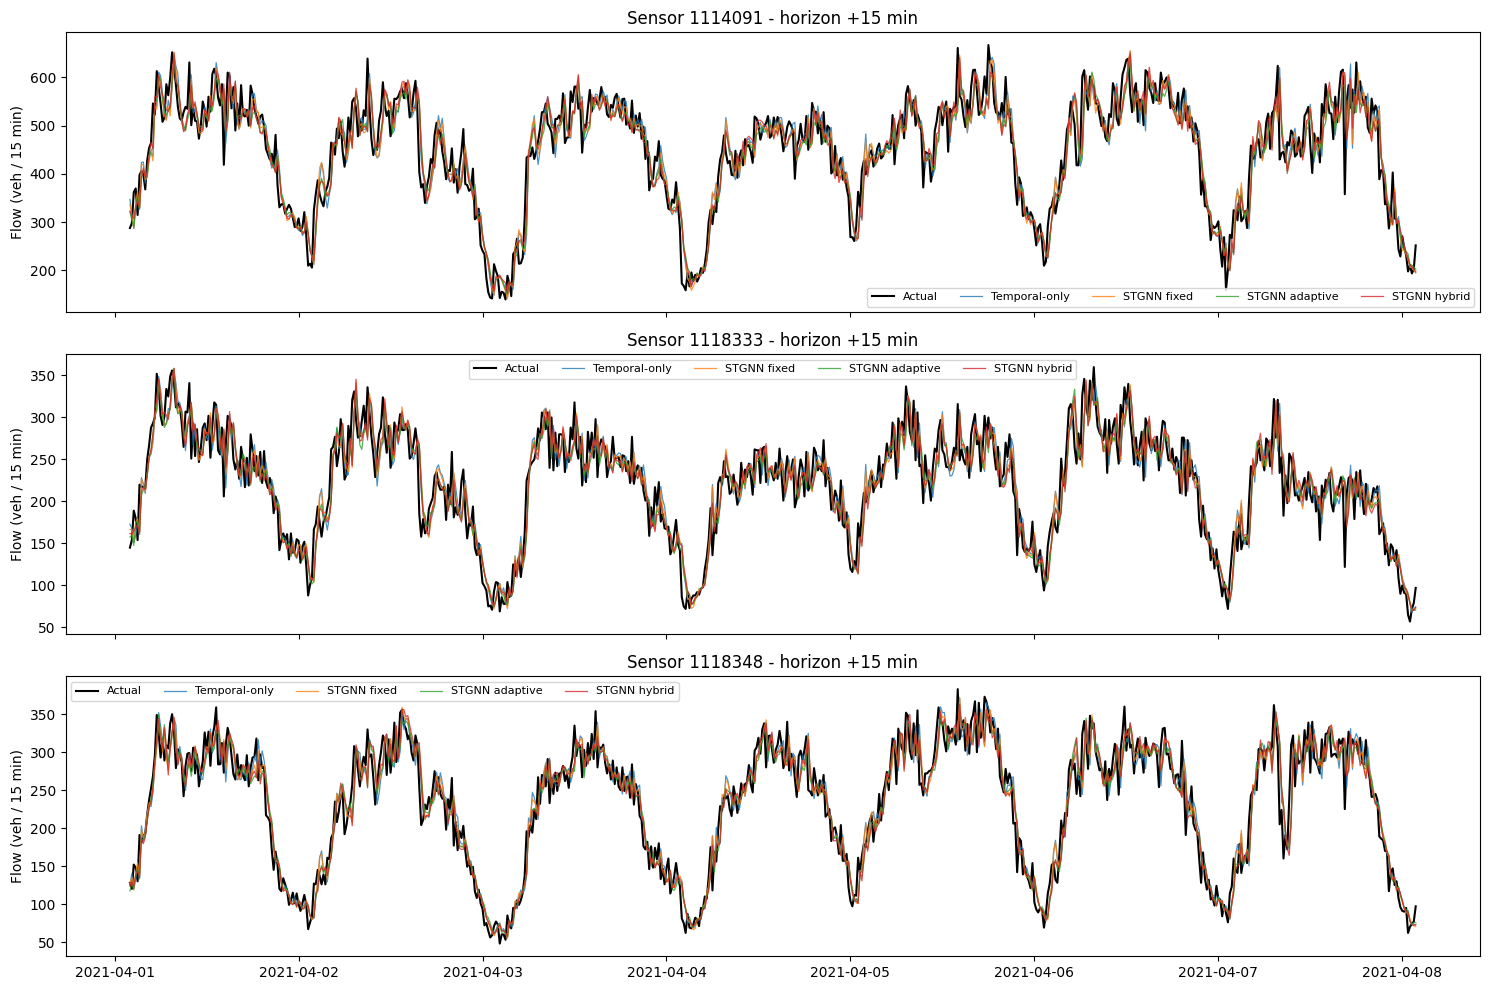

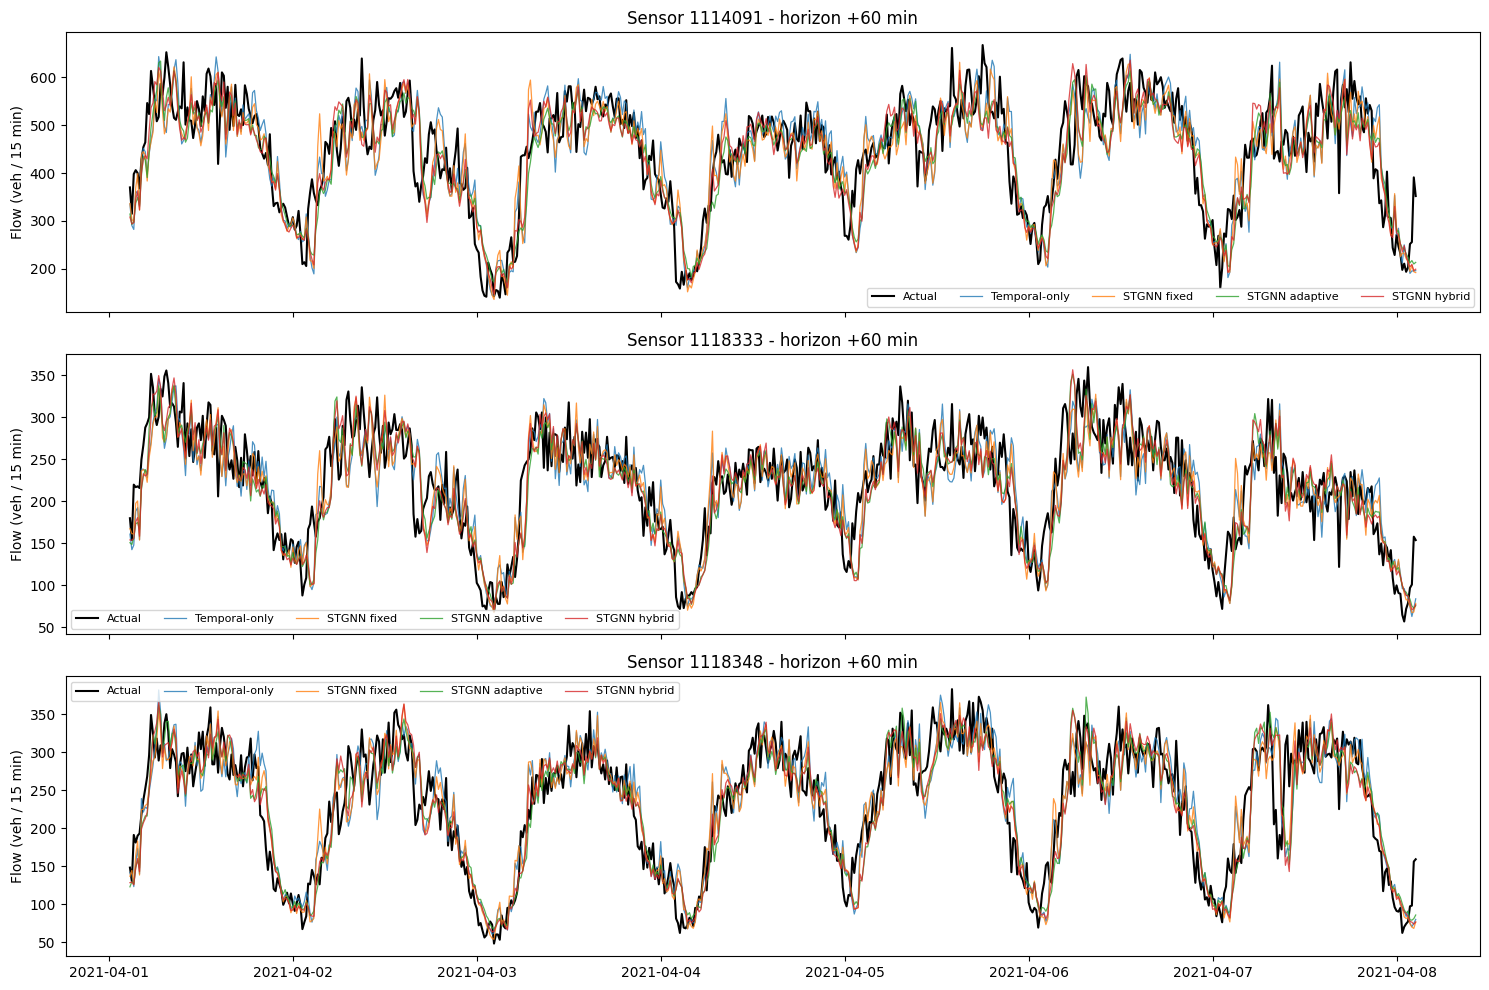

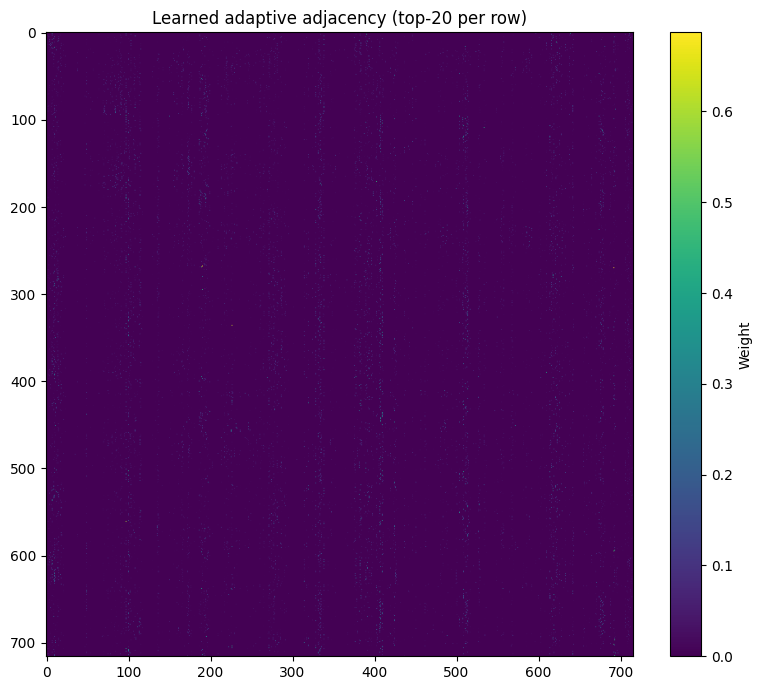

Road-graph density (chance overlap): 0.0338
Top-10 learned links present in road graph: 0.0412
Mean max row weight (uniform over 20 would be 0.05): 0.1901
Learned self-weight (mean diagonal): 0.0022
Median straight-line distance (km): learned 21.61 | random pairs 22.68 | road-graph neighbours 2.37


In [14]:
@torch.no_grad()
def collect_first_week(model, h=0):
    """Predictions for horizon h (0 = +15 min, 3 = +60 min) over the first 7 days of the test set."""
    model.eval(); ds = datasets['test']; count = min(7*96, len(ds))
    actual, predicted, times = [], [], []
    mu, sd = means.to_numpy(), std.to_numpy()
    for start in range(0, count, BATCH):
        samples = [ds[k] for k in range(start, min(count, start + BATCH))]
        x = torch.stack([a[0] for a in samples]).to(DEVICE)
        pred = model(x)[:, h, :].cpu().numpy() * sd + mu
        for j, (_, y, m) in enumerate(samples):
            truth = y[h].numpy() * sd + mu
            truth[m[h].numpy() == 0] = np.nan
            actual.append(truth); predicted.append(pred[j])
            times.append(ds.index[ds.starts[start + j] + 8 + h])
    return np.array(actual), np.array(predicted), times

names = {'temporal': 'Temporal-only', 'fixed': 'STGNN fixed',
         'adaptive': 'STGNN adaptive', 'hybrid': 'STGNN hybrid'}
for h, label in [(0, '+15 min'), (3, '+60 min')]:
    preds = {}
    for k in names:
        actual, preds[k], times = collect_first_week(models[k], h)
    fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
    for ax, j in zip(axes, [0, 1, 2]):
        ax.plot(times, actual[:, j], 'k', lw=1.5, label='Actual')
        for k in names:
            ax.plot(times, preds[k][:, j], lw=0.9, alpha=0.8, label=names[k])
        ax.set_title(f'Sensor {ids[j]} - horizon {label}'); ax.set_ylabel('Flow (veh / 15 min)')
        ax.legend(ncol=5, fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / f'prediction_h{h+1}.png', dpi=150); plt.show()

with torch.no_grad():
    learned = models['adaptive'].adjacency().cpu().numpy()
plt.figure(figsize=(8, 7)); plt.imshow(learned, aspect='auto'); plt.colorbar(label='Weight')
plt.title('Learned adaptive adjacency (top-20 per row)'); plt.tight_layout()
plt.savefig(OUT / 'adaptive_graph.png', dpi=150); plt.show()

N = len(ids)
learned_no_self = learned.copy(); np.fill_diagonal(learned_no_self, 0)
top = np.argsort(-learned_no_self, axis=1)[:, :10]
rr = np.repeat(np.arange(N), 10); cc = top.ravel()

density = B.sum() / (N * (N - 1))
print('Road-graph density (chance overlap):', round(float(density), 4))
print('Top-10 learned links present in road graph:', round(float(B[rr, cc].mean()), 4))
print('Mean max row weight (uniform over 20 would be 0.05):', round(float(learned.max(1).mean()), 4))
print('Learned self-weight (mean diagonal):', round(float(np.diag(learned).mean()), 4))

latcol = next((cols[k] for k in ['lat', 'latitude'] if k in cols), None)
loncol = next((cols[k] for k in ['lng', 'lon', 'longitude'] if k in cols), None)
if latcol and loncol:
    lat = np.deg2rad(pd.to_numeric(sdmeta[latcol], errors='coerce').to_numpy())
    lon = np.deg2rad(pd.to_numeric(sdmeta[loncol], errors='coerce').to_numpy())
    def distance(a, b):
        dlat = lat[a] - lat[b]; dlon = lon[a] - lon[b]
        h_ = np.sin(dlat/2)**2 + np.cos(lat[a])*np.cos(lat[b])*np.sin(dlon/2)**2
        return 12742 * np.arcsin(np.sqrt(np.clip(h_, 0, 1)))
    rng = np.random.default_rng(SEED)
    rand = (rr + rng.integers(1, N, len(rr))) % N
    print('Median straight-line distance (km): learned', round(float(np.nanmedian(distance(rr, cc))), 2),
          '| random pairs', round(float(np.nanmedian(distance(rr, rand))), 2),
          '| road-graph neighbours', round(float(np.nanmedian(distance(*np.nonzero(B)))), 2))

## Q7: Reproducibility and Reporting

In [15]:
config={'seed':SEED,'batch_size':BATCH,'hidden':HIDDEN,'embedding_dim':EMBED,'epochs_max':EPOCHS,'patience':PATIENCE,'learning_rate':LR,'device':str(DEVICE),'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,'processor':platform.processor(),'platform':platform.platform(),'torch':torch.__version__,'train':'2020-01-01 to 2020-12-31','validation':'2021-01-01 to 2021-03-31','test':'2021-04-01 to 2021-12-31','input_steps':8,'output_steps':4,'adaptive_top_k':20}
(OUT/'run_config.json').write_text(json.dumps(config,indent=2)); print(json.dumps(config,indent=2)); print('Saved files:',*[p.name for p in OUT.iterdir()],sep='\n')

{
  "seed": 42,
  "batch_size": 32,
  "hidden": 16,
  "embedding_dim": 8,
  "epochs_max": 40,
  "patience": 5,
  "learning_rate": 0.001,
  "device": "cuda",
  "gpu": "Tesla T4",
  "processor": "x86_64",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.14.1+cu130",
  "train": "2020-01-01 to 2020-12-31",
  "validation": "2021-01-01 to 2021-03-31",
  "test": "2021-04-01 to 2021-12-31",
  "input_steps": 8,
  "output_steps": 4,
  "adaptive_top_k": 20
}
Saved files:
week.png
road_graph.png
temporal.pt
temporal_history.csv
fixed.pt
fixed_history.csv
adaptive.pt
adaptive_history.csv
hybrid.pt
hybrid_history.csv
comparison.csv
prediction.png
adaptive_graph.png
prediction_h1.png
prediction_h4.png
run_config.json
